# Team \#1
## Workshop Open Tools — Vera Rubin Observatory

```Author: Sergio Sotovando```

Last update date: 14/10/2026

**Ver este notebook en [Colab](https://colab.research.google.com/github/ale-munozarancibia/LSST_Hackdays_Medellin_Team1_Characterizing_DIAObjects/blob/main/Project/Team1_Crossmatch_EDFS.ipynb)**

**Objetivo:** extraer SN y AGN de Rubin en el campo EDFS con ALeRCE (TAP) y cruzarlos posicionalmente con catálogos externos del mismo campo usando LSDB:

| Catálogo | Para qué sirve |
|---|---|
| **AllWISE** | Colores en el infrarrojo medio → criterio de AGN (W1 − W2 ≥ 0.8, Stern et al. 2012) |
| **TNS** | Transitorios reportados → confirmar las SN y ver su tipo espectroscópico |

1. Rubin (ALeRCE, `tid = 1`) → SN/AGN con `classifier_id = 3`, `probability ≥ 0.6`, `n_det ≥ 50`
2. Catálogos externos con LSDB (mismo cono)
3. Crossmatch nativo con LSDB y verificación con Astropy

## 1. Paquetes

In [1]:
!pip install pyvo lsdb alerce

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyvo
import lsdb

import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.table import Table, join

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 30)

print("LSDB:", lsdb.__version__)

LSDB: 0.11.0


## 2. Configuración del campo

Se usa **el mismo cono** para Rubin y para los catálogos externos.

In [3]:
FIELDS = {"EDFS": (61.25, -48.46)}
FIELD = "EDFS"
RA0, DEC0 = FIELDS[FIELD]

#RADIUS_ARCSEC = 9738.0               # ~2.705 grados
RADIUS_ARCSEC = 11124.7               # ~3.090 grados
radius_deg = RADIUS_ARCSEC / 3600.0

print(f"{FIELD}: RA={RA0}, Dec={DEC0}, radio={radius_deg:.3f} deg")

EDFS: RA=61.25, Dec=-48.46, radio=3.090 deg


## 3. Rubin desde ALeRCE (TAP)

En la base multisurvey de ALeRCE (`alerce_tap.*`) Rubin/LSST tiene `tid = 1`. El `classifier_id = 3` es el stamp classifier de Rubin.

In [4]:
TAP_URL = "https://tap.alerce.online/tap"
tap_service = pyvo.dal.TAPService(TAP_URL)

def tap_query(query, maxrec=10_000_000):
    result = tap_service.search(query, maxrec=maxrec)
    return result.to_table().to_pandas()

tid = 1             # Rubin/LSST
sid = 1             # diaObjects
classifier_id = 3   # stamp_classifier_rubin_beta_20260421

In [5]:
query = f"""
SELECT
    *
FROM alerce_tap.object AS obj
JOIN alerce_tap.probability AS prob
    ON obj.oid = prob.oid AND obj.sid = prob.sid
JOIN alerce_tap.taxonomy AS tax
    ON prob.classifier_id = tax.classifier_id
   AND prob.class_id = tax.class_id
WHERE
    obj.tid = {tid}
    AND obj.sid = {sid}
    AND prob.classifier_id = {classifier_id}
    AND tax.class_name IN ('SN', 'AGN')
    AND prob.probability >= 0.6
    AND obj.n_det >= 50
    AND CONTAINS(POINT('ICRS', obj.meanra, obj.meandec),
                 CIRCLE('ICRS', {RA0:.7g}, {DEC0:.7g}, {radius_deg:g})) = 1
"""
df_agn_sn = tap_query(query)

print(f"diaObjects SN/AGN en {FIELD}: {len(df_agn_sn)}")
display(df_agn_sn["class_name"].value_counts())

diaObjects SN/AGN en EDFS: 2787


class_name
AGN    2658
SN      129
Name: count, dtype: int64

### 3.1 Tabla limpia de Rubin

El JOIN deja columnas duplicadas (`oid_`, `sid_`, `classifier_id_`, ...). Se conservan solo las útiles.

In [6]:
RUBIN_COLS = ["oid", "meanra", "meandec", "sigmara", "sigmadec",
              "firstmjd", "lastmjd", "n_det", "class_name", "probability"]

df_rubin = (df_agn_sn[RUBIN_COLS]
            .drop_duplicates("oid")
            .reset_index(drop=True))
print(df_rubin.shape)
df_rubin.head()

(2787, 10)


,oid,meanra,meandec,sigmara,sigmadec,firstmjd,lastmjd,n_det,class_name,probability
0,313853497287639046,60.243443,-48.365550,1.219772e-06,1.144682e-06,61024.135340,61095.094433,111,SN,0.878240
1,170019696293707856,60.908246,-48.318395,1.476229e-06,1.516234e-06,61088.098045,61098.102698,207,SN,0.803308
2,170019696438935593,62.952948,-47.749221,3.888888e-07,3.681980e-07,61088.098476,61107.036610,400,SN,0.961168
3,170028486219530368,63.039211,-48.167831,1.936371e-07,1.919700e-07,61090.053544,61095.080183,79,SN,0.624278
4,313871015036846268,61.165461,-47.637616,2.854747e-07,2.929702e-07,61028.328577,61095.094861,109,SN,0.870418


### 3.2 Rubin como catálogo LSDB

La tabla de ALeRCE se convierte en catálogo HATS en memoria para poder cruzarla con `crossmatch` de LSDB.

In [7]:
rubin_cat = lsdb.from_dataframe(df_rubin, ra_column="meanra", dec_column="meandec",
                                catalog_name="rubin_agn_sn")
rubin_cat

,oid,meanra,meandec,sigmara,sigmadec,firstmjd,lastmjd,n_det,class_name,probability
npartitions=1,,,,,,,,,,
"Order: 1, Pixel: 33",int64[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],int32[pyarrow],large_string[pyarrow],float[pyarrow]


## 4. Catálogos externos (LSDB)

`columns=None` carga todas las columnas. Si se da una lista, se usan solo las que existan, y siempre se agregan las columnas de RA/Dec del catálogo.

In [8]:
EXTERNAL_CATALOGS = {
    "AllWISE": dict(
        url="https://data.lsdb.io/hats/wise/allwise",
        radius_arcsec=2.0,
        n_neighbors=1,
        suffix="_wise",
        # Subconjunto de columnas (se usan solo las que existan). None = todas.
        columns=["designation", "source_id", "ra", "dec",
                 "w1mpro", "w1sigmpro", "w2mpro", "w2sigmpro",
                 "w3mpro", "w3sigmpro", "w4mpro", "w4sigmpro",
                 "ext_flg", "cc_flags", "ph_qual"],
    ),
    "TNS": dict(
        url="https://data.lsdb.io/hats/tns",
        radius_arcsec=2.0,
        n_neighbors=1,
        suffix="_tns",
        columns=None,   # TNS es pequeño: se conservan todas las columnas
    ),
}

cone = lsdb.ConeSearch(RA0, DEC0, radius_arcsec=RADIUS_ARCSEC)

In [9]:
def open_external(name, cfg, search_filter):
    """Open an external HATS catalog restricted to the cone,
    keeping only the requested columns that actually exist."""
    meta = lsdb.open_catalog(cfg["url"])
    info = meta.hc_structure.catalog_info
    ra_col, dec_col = info.ra_column, info.dec_column

    if cfg["columns"] is None:
        cols = None
    else:
        cols = [c for c in cfg["columns"] if c in meta.columns]
        missing = [c for c in cfg["columns"] if c not in meta.columns]
        for c in (ra_col, dec_col):
            if c not in cols:
                cols.append(c)
        if missing:
            print(f"  [{name}] columnas no encontradas (se omiten): {missing}")

    cat = lsdb.open_catalog(cfg["url"], columns=cols, search_filter=search_filter)
    print(f"{name}: RA='{ra_col}', Dec='{dec_col}', {len(cat.columns)} columnas")
    return cat, ra_col, dec_col


ext = {}
for name, cfg in EXTERNAL_CATALOGS.items():
    try:
        cat, ra_col, dec_col = open_external(name, cfg, cone)
        ext[name] = dict(cat=cat, ra=ra_col, dec=dec_col, **cfg)
    except Exception as err:
        print(f"No se pudo abrir {name} ({cfg['url']}): {type(err).__name__}: {err}")

print("\nCatálogos listos:", list(ext))

AllWISE: RA='ra', Dec='dec', 15 columnas
TNS: RA='ra', Dec='declination', 23 columnas

Catálogos listos: ['AllWISE', 'TNS']


In [10]:
# Vista rápida de cada catálogo en el campo
for name, e in ext.items():
    print(f"=== {name} ===")
    print(list(e["cat"].columns))
    display(e["cat"].head(3))

=== AllWISE ===
['designation', 'source_id', 'ra', 'dec', 'w1mpro', 'w1sigmpro', 'w2mpro', 'w2sigmpro', 'w3mpro', 'w3sigmpro', 'w4mpro', 'w4sigmpro', 'ext_flg', 'cc_flags', 'ph_qual']


Computing Catalog:   0%|          | 0/2 [00:00<?, ?it/s]

,designation,source_id,ra,dec,w1mpro,w1sigmpro,w2mpro,w2sigmpro,w3mpro,w3sigmpro,w4mpro,w4sigmpro,ext_flg,cc_flags,ph_qual
_healpix_29,,,,,,,,,,,,,,,
2390281061472873433,J040846.16-512838.5,0619m515_ac51-034067,62.192356,-51.477376,12.088,0.022,12.309,0.025,11.847,0.137,8.788,0.214,1,dDH0,AABB
2390281075248688125,J040843.56-512832.2,0619m515_ac51-031372,62.181506,-51.475638,5.375,0.178,5.403,0.052,5.366,0.014,5.238,0.028,0,0000,BAAA
2390281103635237218,J040842.31-512705.3,0619m515_ac51-033353,62.176293,-51.451484,16.507,0.045,17.36,<NA>,13.404,<NA>,9.739,<NA>,0,hHh0,AUUU


=== TNS ===
['objid', 'name_prefix', 'name', 'ra', 'declination', 'redshift', 'typeid', 'type', 'reporting_groupid', 'reporting_group', 'source_groupid', 'source_group', 'discoverydate', 'discoverymag', 'discmagfilter', 'filter', 'reporters', 'time_received', 'internal_names', 'Discovery_ADS_bibcode', 'Class_ADS_bibcodes', 'creationdate', 'lastmodified']


Computing Catalog:   0%|          | 0/2 [00:00<?, ?it/s]

,objid,name_prefix,name,ra,declination,redshift,typeid,type,reporting_groupid,reporting_group,source_groupid,source_group,discoverydate,discoverymag,discmagfilter,filter,reporters,time_received,internal_names,Discovery_ADS_bibcode,Class_ADS_bibcodes,creationdate,lastmodified
_healpix_29,,,,,,,,,,,,,,,,,,,,,,,
2415444459192798718,222765,AT,2026affh,63.23998,-48.284975,<NA>,<NA>,<NA>,59.0,GOTO,59.0,GOTO,2026-09-30 16:29:08.160,19.53,120.0,L,"D. O'Neill, K. Ackley, M. Dyer, J. Lyman, K. Ulaczyk, D. Steeghs, D. Galloway, V. Dhillon, P. O'Brien, G. Ramsay, K. Noysena, R. Kotak, R. Breton, J. Casares, L. Nuttall, R. Starling, B. Gompertz, B. Godson, T. Killestein, A. Kumar, M. Pursiainen, on behalf of GOTO collaboration",2026-10-11 17:43:58,GOTO26kzw,2026TNSTR4094....1O,<NA>,2026-10-11 17:43:59,2026-10-11 17:43:59
2418595988518574505,222380,AT,2026aeud,63.46973,-46.686118,<NA>,<NA>,<NA>,59.0,GOTO,59.0,GOTO,2026-10-08 15:30:50.688,19.3,120.0,L,"D. O'Neill, K. Ackley, M. Dyer, J. Lyman, K. Ulaczyk, D. Steeghs, D. Galloway, V. Dhillon, P. O'Brien, G. Ramsay, K. Noysena, R. Kotak, R. Breton, J. Casares, L. Nuttall, R. Starling, B. Gompertz, B. Godson, T. Killestein, A. Kumar, M. Pursiainen, on behalf of GOTO collaboration",2026-10-08 16:18:17,"GOTO26ktm, ATLAS26mjk",2026TNSTR4052....1O,<NA>,2026-10-08 16:18:20,2026-10-09 08:31:48
2394438199515432362,222342,AT,2026aess,65.831615,-47.990474,<NA>,<NA>,<NA>,48.0,ZTF,165.0,Rubin,2026-02-23 02:32:35.004,23.4645,162.0,r,Robert Stein (UMD),2026-10-07 19:27:06,LSST-P-DO-170046086338576688,2026TNSTR4042....1S,<NA>,2026-10-07 19:27:08,2026-10-07 19:27:08


## 5. Crossmatch con LSDB

`how="left"` conserva **todos** los objetos de Rubin: los que no tienen contraparte quedan con `_dist_arcsec = NaN`. Así se puede calcular directamente la fracción con match por clase.

In [11]:
def to_pandas(df):
    """pyarrow dtypes → numpy-nullable (más fácil de manipular y de pasar a Astropy)."""
    return pd.DataFrame(df).reset_index(drop=True).convert_dtypes(dtype_backend="numpy_nullable")


def lsdb_crossmatch(name, e):
    xm = rubin_cat.crossmatch(
        e["cat"],
        radius_arcsec=e["radius_arcsec"],
        n_neighbors=e["n_neighbors"],
        how="left",
        suffixes=("_rubin", e["suffix"]),
    ).compute()
    df = to_pandas(xm)
    # Quitar el sufijo _rubin para que las columnas de Rubin conserven su nombre original
    df = df.rename(columns={f"{c}_rubin": c for c in RUBIN_COLS})
    df["has_match"] = df["_dist_arcsec"].notna()
    return df


xm = {}
for name, e in ext.items():
    xm[name] = lsdb_crossmatch(name, e)
    n = xm[name].loc[xm[name]["has_match"], "oid"].nunique()
    print(f"{name}: {n} de {df_rubin['oid'].nunique()} objetos Rubin con contraparte "
          f"(radio {e['radius_arcsec']}\")")

/usr/local/lib/python3.13/dist-packages/lsdb/catalog/catalog.py:410: FutureWarning: The default suffix behavior will change from applying suffixes to all columns to only applying suffixes to overlapping columns in a future release.To maintain the current behavior, explicitly set `suffix_method='all_columns'`. To change to the new behavior, set `suffix_method='overlapping_columns'`.
  warnings.warn(


Computing Catalog:   0%|          | 0/21 [00:00<?, ?it/s]

AllWISE: 2169 de 2787 objetos Rubin con contraparte (radio 2.0")


/usr/local/lib/python3.13/dist-packages/lsdb/catalog/catalog.py:410: FutureWarning: The default suffix behavior will change from applying suffixes to all columns to only applying suffixes to overlapping columns in a future release.To maintain the current behavior, explicitly set `suffix_method='all_columns'`. To change to the new behavior, set `suffix_method='overlapping_columns'`.
  warnings.warn(


Computing Catalog:   0%|          | 0/6 [00:00<?, ?it/s]

TNS: 69 de 2787 objetos Rubin con contraparte (radio 2.0")


### 5.1 Resumen por clase

In [12]:
rows = []
for name, df in xm.items():
    best = df.sort_values("_dist_arcsec").drop_duplicates("oid")
    g = best.groupby("class_name")["has_match"].agg(["size", "sum"])
    for cls, r in g.iterrows():
        rows.append(dict(catalogo=name, clase=cls, n_rubin=int(r["size"]),
                         n_con_match=int(r["sum"]), fraccion=r["sum"] / r["size"]))

summary = pd.DataFrame(rows).pivot(index="clase", columns="catalogo",
                                   values=["n_con_match", "fraccion"])
summary.insert(0, "n_rubin", df_rubin.groupby("class_name").size())
display(summary)

n_rubin n_con_match        fraccion          
catalogo             AllWISE   TNS   AllWISE       TNS
clase                                                 
AGN         2658      2088.0  29.0  0.785553  0.010910
SN           129        81.0  40.0  0.627907  0.310078

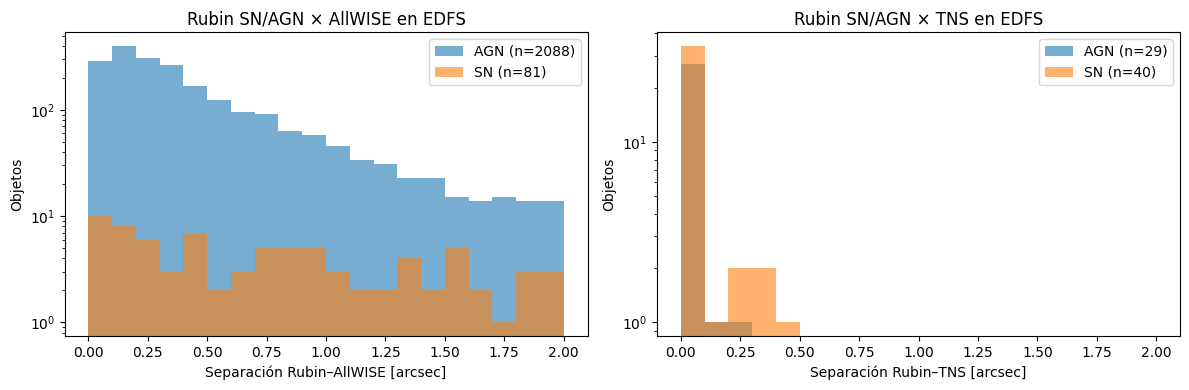

In [13]:
fig, axes = plt.subplots(1, len(xm), figsize=(6 * len(xm), 4), squeeze=False)
for ax, (name, df) in zip(axes[0], xm.items()):
    for cls in ["AGN", "SN"]:
        sep = df.loc[df["has_match"] & (df["class_name"] == cls), "_dist_arcsec"].astype(float)
        ax.hist(sep, bins=np.linspace(0, ext[name]["radius_arcsec"], 21), alpha=0.6,
                label=f"{cls} (n={len(sep)})")
    ax.set_xlabel(f"Separación Rubin–{name} [arcsec]")
    ax.set_ylabel("Objetos")
    ax.set_title(f"Rubin SN/AGN × {name} en {FIELD}")
    ax.legend()
plt.tight_layout()
plt.show()

## 6. Verificación con Astropy

Mismo crossmatch pero siguiendo el esqueleto del equipo: catálogo externo → pandas → `astropy.Table` → `SkyCoord.search_around_sky`. Debe dar el mismo número de objetos con match que LSDB.

In [16]:
def astropy_crossmatch(table_1, table_2, ra_1, dec_1, ra_2, dec_2,
                       match_radius=1.0 * u.arcsec,
                       table_names=("table1", "table2")):
    """Positional crossmatch of two Astropy Tables.
    Returns every pair within match_radius, sorted by separation."""
    coord_1 = SkyCoord(ra=np.asarray(table_1[ra_1], dtype=float) * u.deg,
                       dec=np.asarray(table_1[dec_1], dtype=float) * u.deg)
    coord_2 = SkyCoord(ra=np.asarray(table_2[ra_2], dtype=float) * u.deg,
                       dec=np.asarray(table_2[dec_2], dtype=float) * u.deg)

    idx_1, idx_2, separation, _ = coord_2.search_around_sky(coord_1, match_radius)

    if len(idx_1) == 0:
        # Sin pares dentro del radio: astropy.join no acepta tablas vacías
        print(f"Sin matches dentro de {match_radius}.")
        return Table()

    matched_1 = table_1[idx_1].copy()
    matched_2 = table_2[idx_2].copy()

    match_id = np.arange(len(idx_1), dtype=int)
    matched_1["match_id"] = match_id
    matched_2["match_id"] = match_id
    matched_1["separation_arcsec"] = separation.to_value(u.arcsec)

    crossmatch = join(matched_1, matched_2, keys="match_id", join_type="inner",
                      table_names=list(table_names),
                      uniq_col_name="{col_name}_{table_name}")
    crossmatch.sort("separation_arcsec")
    return crossmatch

In [17]:
table_1 = Table.from_pandas(df_rubin)
xm_astropy = {}

for name, e in ext.items():
    df_ext = to_pandas(e["cat"].compute())
    # Para verificar el match basta con columnas numéricas (evita problemas con texto/anidadas)
    df_ext = df_ext.select_dtypes(include="number")
    table_2 = Table.from_pandas(df_ext)

    res = astropy_crossmatch(table_1, table_2, "meanra", "meandec", e["ra"], e["dec"],
                             match_radius=e["radius_arcsec"] * u.arcsec,
                             table_names=("rubin", e["suffix"].lstrip("_")))
    xm_astropy[name] = res
    n_astropy = len(set(res["oid"])) if len(res) else 0
    n_lsdb = xm[name].loc[xm[name]["has_match"], "oid"].nunique()
    print(f"{name}: {len(df_ext):,} fuentes en el campo | "
          f"objetos con match → Astropy: {n_astropy}, LSDB: {n_lsdb}")

Computing Catalog:   0%|          | 0/8 [00:00<?, ?it/s]

AllWISE: 573,282 fuentes en el campo | objetos con match → Astropy: 2169, LSDB: 2169


Computing Catalog:   0%|          | 0/2 [00:00<?, ?it/s]

TNS: 286 fuentes en el campo | objetos con match → Astropy: 69, LSDB: 69


## 8. SN con TNS: transitorios reportados

TNS (Transient Name Server) es el registro oficial de transitorios. Un match indica que el objeto ya fue reportado; si tiene tipo espectroscópico (por ejemplo `SN Ia`, `SN II`), sirve como **verdad de referencia** para evaluar al clasificador de Rubin.

Los nombres de columna de TNS se detectan automáticamente porque pueden variar.

In [18]:
def find_col(columns, candidates):
    for c in candidates:
        for variant in (c, f"{c}_tns"):
            if variant in columns:
                return variant
    return None

if "TNS" in xm:
    tns = (xm["TNS"][xm["TNS"]["has_match"]]
           .sort_values("_dist_arcsec").drop_duplicates("oid").copy())
    cols = tns.columns
    TNS_NAME = find_col(cols, ["name", "objname", "fullname", "name_prefix"])
    TNS_TYPE = find_col(cols, ["type", "obj_type", "objtype", "classification"])
    TNS_Z = find_col(cols, ["redshift", "z"])
    TNS_DATE = find_col(cols, ["discoverydate", "discovery_date", "disc_date"])
    print("Columnas TNS detectadas:", dict(nombre=TNS_NAME, tipo=TNS_TYPE, z=TNS_Z, fecha=TNS_DATE))

    show = ["oid", "class_name", "probability", "_dist_arcsec"] + \
           [c for c in (TNS_NAME, TNS_TYPE, TNS_Z, TNS_DATE) if c]
    display(tns[show].sort_values(["class_name", "_dist_arcsec"]))

Columnas TNS detectadas: {'nombre': 'name_tns', 'tipo': 'type_tns', 'z': 'redshift_tns', 'fecha': 'discoverydate_tns'}


,oid,class_name,probability,_dist_arcsec,name_tns,type_tns,redshift_tns,discoverydate_tns
62,313950161909317636,AGN,0.824912,0.001801,2026emn,<NA>,<NA>,2026-02-25 09:36:00.000
67,313853497291309068,AGN,0.771886,0.002533,2026elz,<NA>,<NA>,2026-02-25 05:31:12.000
...,...,...,...,...,...,...,...,...
12,170028486049136782,SN,0.963386,0.389839,2025onk,<NA>,<NA>,2025-06-13 19:44:07.584
1,313637935719645190,SN,0.976553,0.401184,2025able,<NA>,<NA>,2025-10-23 05:14:06.432


In [19]:
# Clase de Rubin vs. tipo en TNS
if "TNS" in xm and len(tns) and TNS_TYPE:
    tipo = tns[TNS_TYPE].astype("string").fillna("sin clasificar")
    tipo = tipo.where(tipo.str.strip() != "", "sin clasificar")
    display(pd.crosstab(tns["class_name"], tipo, margins=True))

type_tns,sin clasificar,All
class_name,,
AGN,29,29
SN,40,40
All,69,69


**Cómo leerlo:**
- **SN de Rubin con tipo `SN …` en TNS** → acierto del clasificador.
- **SN de Rubin con tipo `AGN`/`QSO`/`TDE`/`CV`** → posible confusión del clasificador.
- **AGN de Rubin que aparecen en TNS** → alguien reportó su variabilidad como transitorio. Es común en AGN con fulguraciones; conviene revisar sus curvas de luz.
- **Sin match en TNS** → no reportado (todavía), no necesariamente falso.

## 9. Links de inspección en ALeRCE: objetos con contraparte en TNS

Para cada objeto de Rubin que coincide con TNS se generan links al explorador
de ALeRCE (Rubin/LSST), ordenados por probabilidad del clasificador, para
revisar a ojo las curvas de luz y los stamps.
Prioridad de revisión:
  - AGN de Rubin con match en TNS → reportado como transitorio, posible error.
  - SN de Rubin cuyo tipo en TNS no es "SN …" → posible confusión.

In [23]:
CLASSIFIER_NAME = "stamp_classifier_rubin_beta_20260421"   # classifier_id = 3
ALERCE_LSST_URL = "https://lsst.alerce.online/?"
BATCH_SIZE = 100
TOP_N = None          # None = todos los objetos con match; o un entero para ver solo los top N

In [24]:
def alerce_url(oids, classifier_name=CLASSIFIER_NAME):
    """URL del explorador de ALeRCE con uno o varios oid."""
    suffix = (f"&count=true&page=1&perPage=1000&sortDesc=true"
              f"&selectedClassifier={classifier_name}")
    return ALERCE_LSST_URL + "&".join(f"oid={o}" for o in oids) + suffix


def dourlbatches(df, classifier_name, class_name, N=None, batchsize=BATCH_SIZE):
    """Imprime links en lotes para los objetos de `class_name`,
    del más probable al menos probable según el clasificador."""
    sel = (df.loc[df["class_name"] == class_name]
             .sort_values("probability", ascending=False))
    if N is not None:
        sel = sel.iloc[:N]
    n = sel.shape[0]
    print(f"Campo: {FIELD}\nClassifier: {classifier_name}\nClass: {class_name}\n"
          f"#objetos con match en TNS: {n} "
          f"(en lotes de no más de {min(batchsize, n)} elementos)")
    for ibatch in range(int(np.ceil(n / batchsize))):
        chunk = sel.index[ibatch * batchsize:(ibatch + 1) * batchsize]
        print(f"Batch {ibatch + 1}")
        print(alerce_url(chunk, classifier_name))
    print()

In [25]:
if "TNS" in xm and len(tns):
    # Índice = oid, como espera dourlbatches
    tns_links = tns.set_index("oid")

    # --- Links en lote por clase de Rubin ---
    for class_name in ["AGN", "SN"]:
        dourlbatches(tns_links, CLASSIFIER_NAME, class_name, N=TOP_N)

    # --- Link individual por objeto, con su información de TNS ---
    tipo_tns = (tns_links[TNS_TYPE].astype("string").fillna("sin clasificar")
                if TNS_TYPE else pd.Series("sin clasificar", index=tns_links.index))
    nombre_tns = (tns_links[TNS_NAME].astype("string")
                  if TNS_NAME else pd.Series("", index=tns_links.index))

    revisar = pd.DataFrame({
        "class_name": tns_links["class_name"],
        "probability": tns_links["probability"].astype(float),
        "nombre_tns": nombre_tns,
        "tipo_tns": tipo_tns,
    })
    # Bandera: AGN en TNS, o SN de Rubin con un tipo TNS que no es SN
    revisar["sospechoso"] = (
        (revisar["class_name"] == "AGN")
        | ((revisar["class_name"] == "SN")
           & (revisar["tipo_tns"] != "sin clasificar")
           & ~revisar["tipo_tns"].str.startswith("SN"))
    )
    revisar = revisar.sort_values(["sospechoso", "class_name", "probability"],
                                  ascending=[False, True, False])

    print(f"=== Objetos con match en TNS en {FIELD}: {len(revisar)} "
          f"({int(revisar['sospechoso'].sum())} marcados como sospechosos) ===\n")
    for oid, r in revisar.iterrows():
        marca = "Alerta" if r["sospechoso"] else "   "
        print(f"{marca}{oid}  Rubin={r['class_name']:<3} p={r['probability']:.3f}  "
              f"TNS={r['nombre_tns']} ({r['tipo_tns']})")
        print(f"      {alerce_url([oid])}")
else:
    print("No hay objetos con match en TNS para generar links.")

Campo: EDFS
Classifier: stamp_classifier_rubin_beta_20260421
Class: AGN
#objetos con match en TNS: 29 (en lotes de no más de 29 elementos)
Batch 1
https://lsst.alerce.online/?oid=313871013537906708&oid=313928194266234898&oid=313972153257558986&oid=313928194199650329&oid=313761042400804999&oid=313756671695913113&oid=313765480964816937&oid=313690717384867850&oid=313831458488713244&oid=313664312967168019&oid=313994145051443228&oid=170028486388351098&oid=313950161909317636&oid=313708289172439116&oid=170046086338576688&oid=313664313300090962&oid=313761042410242140&oid=313936964401234113&oid=313756671825412125&oid=313853497291309068&oid=313699506876579877&oid=313681913638813716&oid=313980945119576112&oid=313967752699183114&oid=313703904917848098&oid=313831458340864047&oid=170028485844664382&oid=313893022950490177&oid=170019696432119865&count=true&page=1&perPage=1000&sortDesc=true&selectedClassifier=stamp_classifier_rubin_beta_20260421

Campo: EDFS
Classifier: stamp_classifier_rubin_beta_2026

## 10. Tabla final y guardado

In [ ]:
final = df_rubin.copy()

if "AllWISE" in xm:
    # Define 'wise' using the crossmatch results stored in xm
    wise = xm["AllWISE"][xm["AllWISE"]["has_match"]].sort_values("_dist_arcsec").drop_duplicates("oid").copy()

    # Add default or calculated columns if they are not present in AllWISE (such as Stern AGN criteria columns)
    if "W1_W2" not in wise.columns and "w1mpro" in wise.columns and "w2mpro" in wise.columns:
        wise["W1"] = wise["w1mpro"]
        wise["W2"] = wise["w2mpro"]
        if "w3mpro" in wise.columns:
            wise["W3"] = wise["w3mpro"]
        wise["W1_W2"] = wise["W1"] - wise["W2"]
        if "w3mpro" in wise.columns:
            wise["W2_W3"] = wise["W2"] - wise["w3mpro"]
        else:
            wise["W2_W3"] = pd.NA
        wise["agn_stern12"] = wise["W1_W2"] >= 0.8

    keep_wise = [c for c in ["W1", "W2", "W3", "W1_W2", "W2_W3", "agn_stern12"] if c in wise.columns]
    final = final.merge(
        wise[["oid", "_dist_arcsec"] + keep_wise]
        .rename(columns={"_dist_arcsec": "sep_wise_arcsec"}),
        on="oid", how="left")

if "TNS" in xm:
    keep = [c for c in (TNS_NAME, TNS_TYPE, TNS_Z, TNS_DATE) if c]
    final = final.merge(
        tns[["oid", "_dist_arcsec"] + keep]
        .rename(columns={"_dist_arcsec": "sep_tns_arcsec"}),
        on="oid", how="left")

display(final)

final.to_csv(f"rubin_agn_sn_{FIELD}_xmatch_wise_tns.csv", index=False)
for name, df in xm.items():
    df.to_csv(f"rubin_x_{name.lower()}_{FIELD}.csv", index=False)
print("Guardado.")